# 3.6 Joint visual–semantic embedding

This notebook reports the completed visual–semantic embedding (VSE) stage. It loads the saved category-specific checkpoints, reconstructs their validation inputs, and visualizes image–title alignment in the learned 512-dimensional space. It does not retrain any model.

**Evaluation boundary.** Retrieval is measured against weak seller-title pairs. Exact-pair retrieval can penalize legitimate duplicate or semantically equivalent descriptions, and it is not an independent gold evaluation of visual attributes.

In [1]:
from pathlib import Path
import json, collections, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.decomposition import PCA
from fashion_vn.model import JointEmbedding, ranking_loss

ROOT=Path.cwd()
if not (ROOT/'fashion_vn').exists(): ROOT=ROOT.parent
MODEL_ROOT=ROOT/'models/local_resnet18_set_v2'; CACHE=ROOT/'outputs/cache_resnet18'
MANIFEST=ROOT/'outputs/prepared_set_v2/manifest.jsonl'; FIG_DIR=ROOT/'outputs/figures/joint_embedding'
FIG_DIR.mkdir(parents=True,exist_ok=True)
rows=[json.loads(x) for x in MANIFEST.read_text(encoding='utf-8').splitlines()]
run=json.loads((MODEL_ROOT/'run_summary.json').read_text(encoding='utf-8'))
trained={k:v for k,v in run.items() if v.get('status')=='trained_unvalidated'}
COLORS={'blue':'#386CB0','green':'#59A14F','orange':'#E68600','purple':'#8E63B5','red':'#CC4F4F','gray':'#929292'}
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':12,'axes.labelsize':11,'figure.titlesize':16})
def savefig(fig,stem):
    fig.savefig(FIG_DIR/f'{stem}.png',dpi=300,bbox_inches='tight',facecolor='white')
    fig.savefig(FIG_DIR/f'{stem}.svg',bbox_inches='tight',facecolor='white')
    plt.show(); plt.close(fig)
def bow_tensor(rs,vocab):
    lookup={t:i for i,t in enumerate(vocab)}; B=torch.zeros(len(rs),len(vocab))
    for i,r in enumerate(rs):
        for t in r['tokens']:
            if t in lookup: B[i,lookup[t]]+=1
    return B
def recall_at_k(S,k,axis=1):
    order=np.argsort(-S,axis=axis)
    if axis==1: return np.mean([i in order[i,:k] for i in range(len(S))])
    return np.mean([j in order[:k,j] for j in range(len(S))])
print('Trained categories:',list(trained))

Trained categories: ['top', 'dress', 'pants', 'skirt', 'jacket', 'bag', 'hat', 'set']


## Reconstruct frozen validation embeddings

For each category, cached ResNet18 maps are globally averaged, linearly projected, and L2-normalized. Bag-of-words title vectors are averaged through the learned word embedding and L2-normalized.

In [2]:
results={}; metric_rows=[]; rng=np.random.default_rng(42)
for cat,status in trained.items():
    ck=torch.load(MODEL_ROOT/cat/'vse.pt',map_location='cpu',weights_only=True)
    vocab=ck['vocab']; vocab_set=set(vocab)
    eligible=[r for r in rows if r['category']==cat and r['image_status']=='ok'
              and not any(f in r['flags'] for f in ('listing_multiple_variants','possible_negation_review'))]
    val=[r for r in eligible if r['split']=='val' and vocab_set.intersection(r['tokens'])]
    X=torch.from_numpy(np.stack([np.load(CACHE/f"{r['image_sha256']}.npy").astype(np.float32).mean((1,2)) for r in val]))
    B=bow_tensor(val,vocab); model=JointEmbedding(X.shape[1],len(vocab),ck['dim']); model.load_state_dict(ck['state_dict']); model.eval()
    with torch.no_grad(): I=model.image(X); T=model.text(B); S=(I@T.T).numpy()
    pos=np.diag(S); groups=np.asarray([r['group_id'] for r in val]); valid=groups[:,None]!=groups[None,:]
    same=(B[:,None,:]==B[None,:,:]).all(-1).numpy(); valid &= ~same
    neg=S[valid]; sample_neg=rng.choice(neg,size=min(len(neg),len(pos)*20),replace=False)
    ranks_i=np.asarray([np.where(np.argsort(-S[i])==i)[0][0]+1 for i in range(len(val))])
    ranks_t=np.asarray([np.where(np.argsort(-S[:,j])==j)[0][0]+1 for j in range(len(val))])
    row={'category':cat,'validation_pairs':len(val),'vocabulary':len(vocab),
         'positive_cosine_mean':float(pos.mean()),'negative_cosine_mean':float(sample_neg.mean()),
         'cosine_gap':float(pos.mean()-sample_neg.mean()),
         'i2t_R1':recall_at_k(S,1,1),'i2t_R5':recall_at_k(S,5,1),'i2t_R10':recall_at_k(S,10,1),
         't2i_R1':recall_at_k(S,1,0),'t2i_R5':recall_at_k(S,5,0),'t2i_R10':recall_at_k(S,10,0),
         'i2t_median_rank':float(np.median(ranks_i)),'t2i_median_rank':float(np.median(ranks_t)),
         'checkpoint_best_loss':status['best_val_weak_ranking_loss']}
    metric_rows.append(row); results[cat]={'rows':val,'I':I.numpy(),'T':T.numpy(),'S':S,'pos':pos,'neg':sample_neg,'vocab':vocab}
metrics=pd.DataFrame(metric_rows)
metrics.to_csv(FIG_DIR/'3_6_validation_alignment_metrics.csv',index=False,encoding='utf-8-sig')
display(metrics.round(4))

,category,validation_pairs,vocabulary,positive_cosine_mean,negative_cosine_mean,cosine_gap,i2t_R1,i2t_R5,i2t_R10,t2i_R1,t2i_R5,t2i_R10,i2t_median_rank,t2i_median_rank,checkpoint_best_loss
0,top,240,594,0.2484,0.0106,0.2378,0.0958,0.2375,0.3583,0.1083,0.3042,0.4083,20.0,15.0,0.1582
1,dress,198,490,0.1883,0.0032,0.1852,0.0808,0.2778,0.3687,0.1010,0.2778,0.3939,19.5,20.0,0.1659
2,pants,139,382,0.2500,0.0067,0.2433,0.1295,0.3885,0.5683,0.1511,0.4460,0.5971,7.0,7.0,0.1449
3,skirt,94,253,0.2155,-0.0003,0.2158,0.0745,0.3191,0.5957,0.1064,0.4149,0.5532,9.0,9.0,0.1538
4,jacket,134,382,0.1935,0.0024,0.1911,0.1493,0.3657,0.5149,0.1194,0.3657,0.5075,10.0,9.5,0.1449
5,bag,60,187,0.1692,0.0055,0.1637,0.2167,0.3667,0.5833,0.2000,0.4000,0.5167,8.0,9.0,0.2015
6,hat,36,174,0.2585,0.0039,0.2547,0.1944,0.5833,0.8333,0.2222,0.6389,0.8889,4.0,4.5,0.1320
7,set,68,241,0.2739,0.0062,0.2676,0.2059,0.4559,0.7206,0.1912,0.5294,0.6912,7.0,5.0,0.1513


## 3.6.1 Training data and embedding configuration

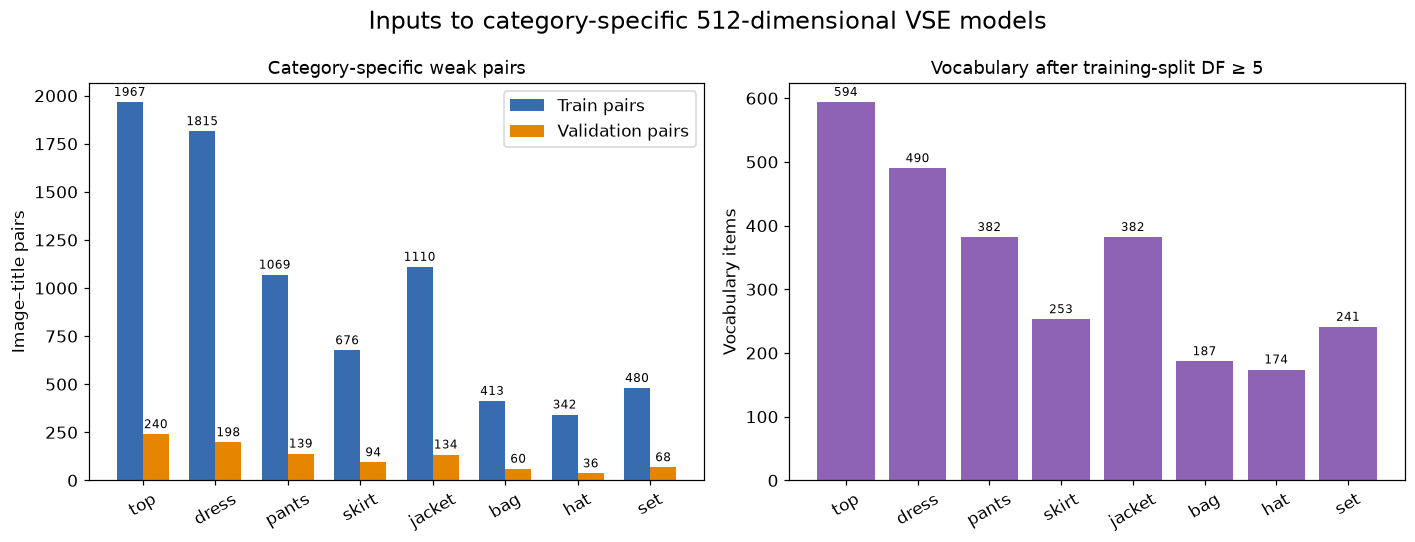

In [3]:
summary=pd.DataFrame([{'category':c,'train':s['train'],'validation':s['val'],'vocabulary':s['vocabulary'],
 'embedding_dim':s['configuration']['dim'],'epochs_run':s['epochs_run']} for c,s in trained.items()])
summary.to_csv(FIG_DIR/'3_6_1_embedding_run_summary.csv',index=False,encoding='utf-8-sig')
fig,axes=plt.subplots(1,2,figsize=(13,5)); x=np.arange(len(summary)); w=.36
axes[0].bar(x-w/2,summary.train,w,label='Train pairs',color=COLORS['blue']); axes[0].bar(x+w/2,summary.validation,w,label='Validation pairs',color=COLORS['orange'])
axes[0].set_xticks(x,summary.category,rotation=30); axes[0].set_ylabel('Image–title pairs'); axes[0].set_title('Category-specific weak pairs'); axes[0].legend()
axes[1].bar(summary.category,summary.vocabulary,color=COLORS['purple']); axes[1].tick_params(axis='x',rotation=30); axes[1].set_ylabel('Vocabulary items'); axes[1].set_title('Vocabulary after training-split DF ≥ 5')
for ax in axes:
    for c in ax.containers: ax.bar_label(c,fontsize=8,padding=2)
fig.suptitle('Inputs to category-specific 512-dimensional VSE models')
fig.tight_layout(); savefig(fig,'figure_3_6_1_embedding_inputs')

## 3.6.2 Bidirectional ranking-loss histories

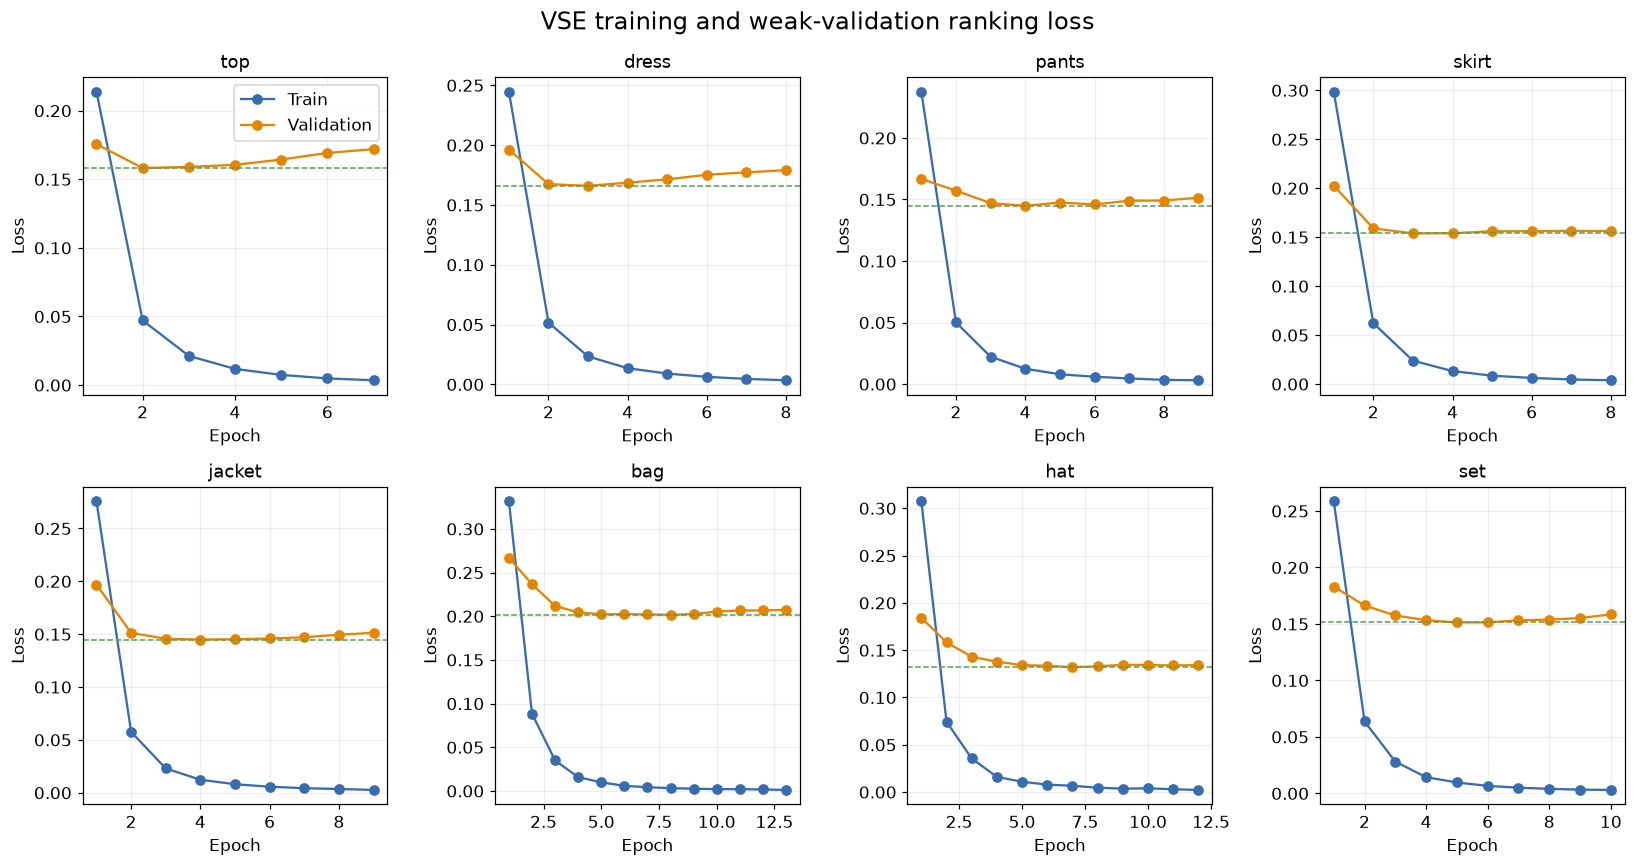

In [4]:
fig,axes=plt.subplots(2,4,figsize=(15,8)); axes=axes.ravel()
for ax,(cat,status) in zip(axes,trained.items()):
    h=json.loads((MODEL_ROOT/cat/'training_history.json').read_text())
    ax.plot([z['epoch'] for z in h],[z['train_loss'] for z in h],marker='o',label='Train',color=COLORS['blue'])
    ax.plot([z['epoch'] for z in h],[z['val_weak_ranking_loss'] for z in h],marker='o',label='Validation',color=COLORS['orange'])
    ax.axhline(status['best_val_weak_ranking_loss'],color=COLORS['green'],ls='--',lw=1); ax.set_title(cat); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss'); ax.grid(alpha=.2)
axes[0].legend(); [ax.axis('off') for ax in axes[len(trained):]]
fig.suptitle('VSE training and weak-validation ranking loss')
fig.tight_layout(); savefig(fig,'figure_3_6_2_training_histories')

## 3.6.3 Matched and mismatched cosine similarities

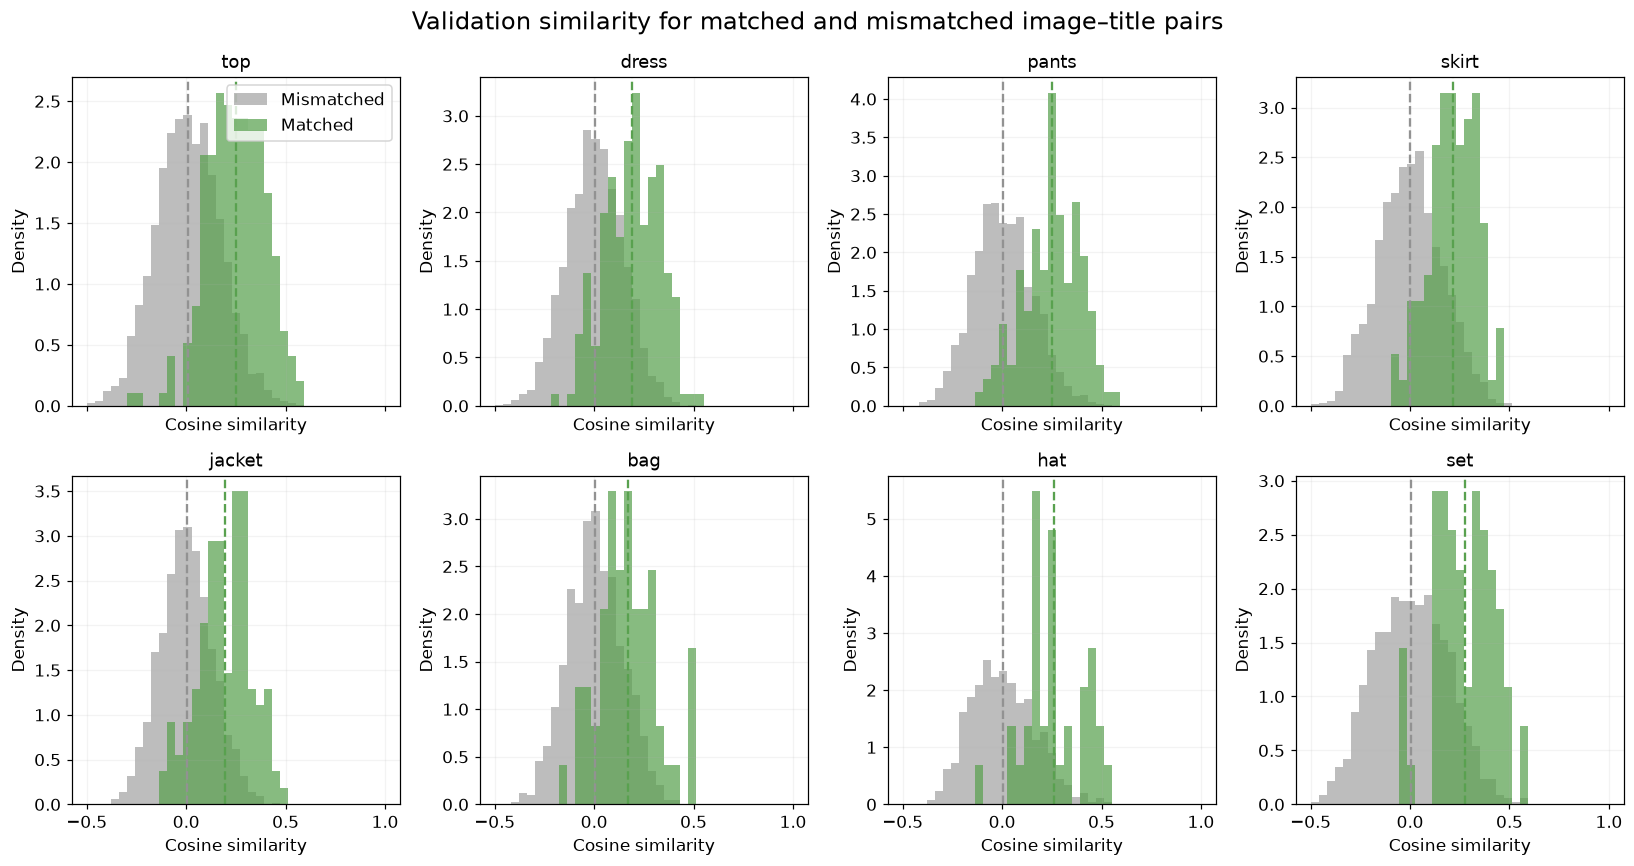

In [5]:
fig,axes=plt.subplots(2,4,figsize=(15,8),sharex=True); axes=axes.ravel()
for ax,(cat,r) in zip(axes,results.items()):
    bins=np.linspace(-.5,1,38); ax.hist(r['neg'],bins=bins,density=True,alpha=.6,label='Mismatched',color=COLORS['gray'])
    ax.hist(r['pos'],bins=bins,density=True,alpha=.72,label='Matched',color=COLORS['green'])
    ax.axvline(r['pos'].mean(),color=COLORS['green'],ls='--'); ax.axvline(r['neg'].mean(),color=COLORS['gray'],ls='--')
    ax.set_title(cat); ax.set_xlabel('Cosine similarity'); ax.set_ylabel('Density'); ax.grid(alpha=.15)
axes[0].legend(); [ax.axis('off') for ax in axes[len(results):]]
fig.suptitle('Validation similarity for matched and mismatched image–title pairs')
fig.tight_layout(); savefig(fig,'figure_3_6_3_similarity_distributions')

## 3.6.4 Bidirectional weak-pair retrieval

Image-to-text (I→T) and text-to-image (T→I) retrieval use the exact paired validation item as the target. Recall@K is therefore a strict proxy for alignment, especially when several products have equivalent titles.

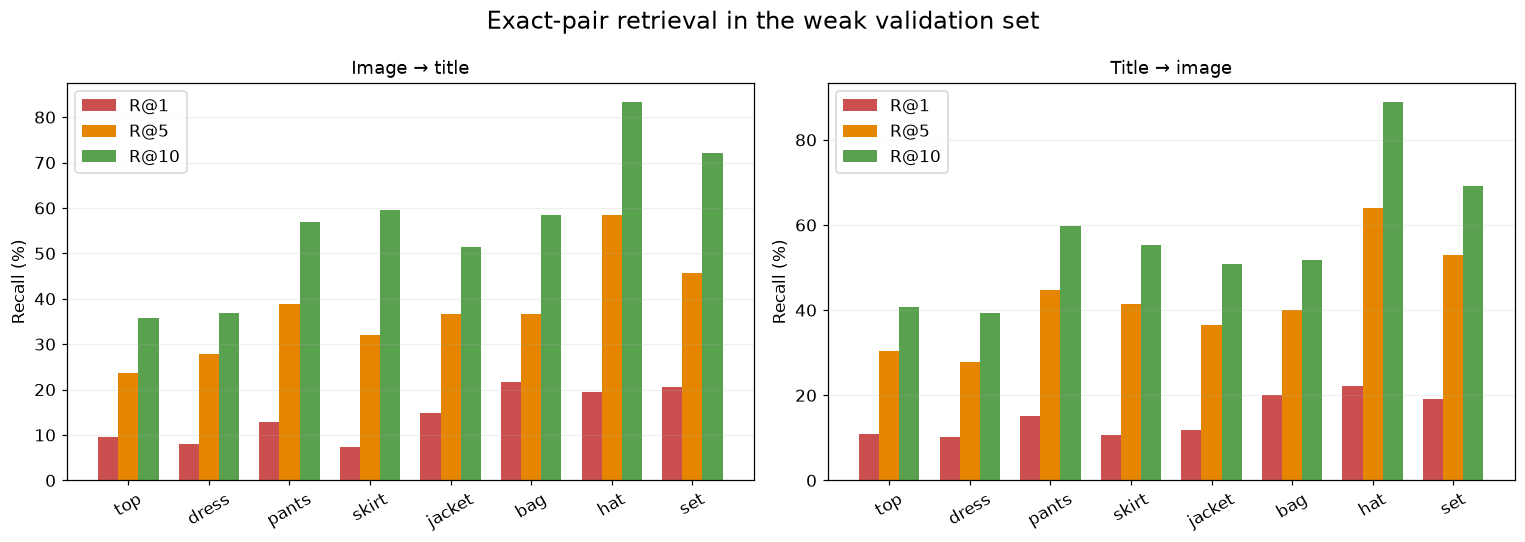

In [6]:
fig,axes=plt.subplots(1,2,figsize=(14,5)); x=np.arange(len(metrics)); w=.25
for j,(col,label,color) in enumerate([('i2t_R1','R@1',COLORS['red']),('i2t_R5','R@5',COLORS['orange']),('i2t_R10','R@10',COLORS['green'])]): axes[0].bar(x+(j-1)*w,100*metrics[col],w,label=label,color=color)
for j,(col,label,color) in enumerate([('t2i_R1','R@1',COLORS['red']),('t2i_R5','R@5',COLORS['orange']),('t2i_R10','R@10',COLORS['green'])]): axes[1].bar(x+(j-1)*w,100*metrics[col],w,label=label,color=color)
for ax,title in zip(axes,['Image → title','Title → image']):
    ax.set_xticks(x,metrics.category,rotation=30); ax.set_ylabel('Recall (%)'); ax.set_title(title); ax.legend(); ax.grid(axis='y',alpha=.2)
fig.suptitle('Exact-pair retrieval in the weak validation set')
fig.tight_layout(); savefig(fig,'figure_3_6_4_bidirectional_retrieval')

## 3.6.5 Image–title similarity matrix

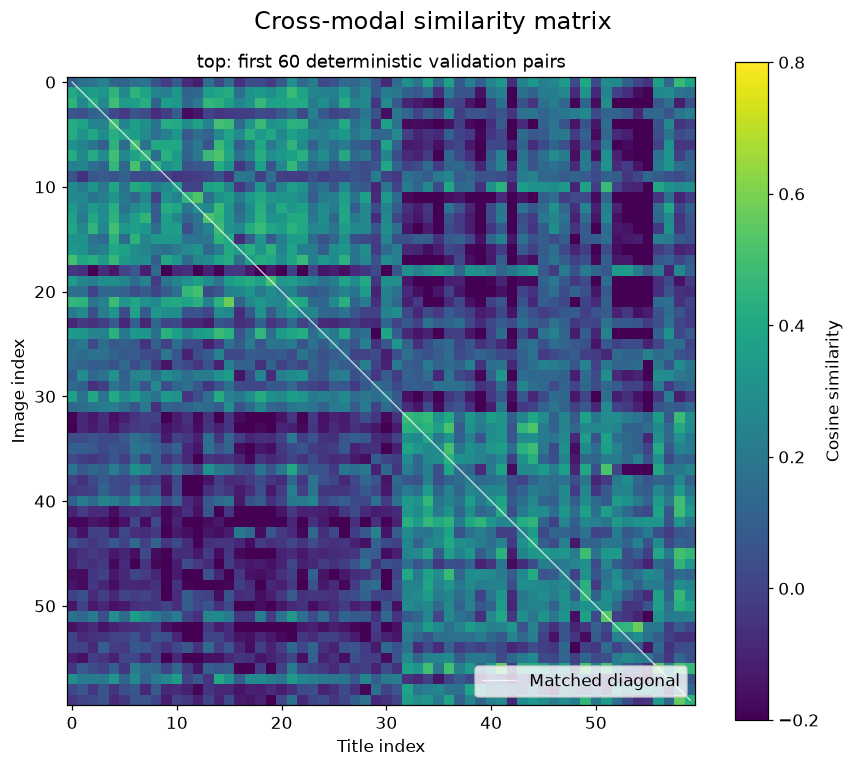

In [7]:
CATEGORY='top'; r=results[CATEGORY]; n=min(60,len(r['rows'])); ids=np.arange(n); matrix=r['S'][ids][:,ids]
fig,ax=plt.subplots(figsize=(8,7)); im=ax.imshow(matrix,cmap='viridis',vmin=-.2,vmax=.8)
ax.plot(np.arange(n),np.arange(n),color='white',lw=.8,alpha=.8,label='Matched diagonal')
ax.set_xlabel('Title index'); ax.set_ylabel('Image index'); ax.set_title(f'{CATEGORY}: first {n} deterministic validation pairs'); ax.legend(loc='lower right')
fig.colorbar(im,ax=ax,label='Cosine similarity'); fig.suptitle('Cross-modal similarity matrix')
fig.tight_layout(); savefig(fig,'figure_3_6_5_similarity_matrix')

## 3.6.6 Joint embedding geometry

The image and title vectors are projected together for visualization. Connecting lines show exact validation pairs; short lines indicate local alignment in this two-dimensional PCA view, although PCA does not preserve all 512-dimensional distances.

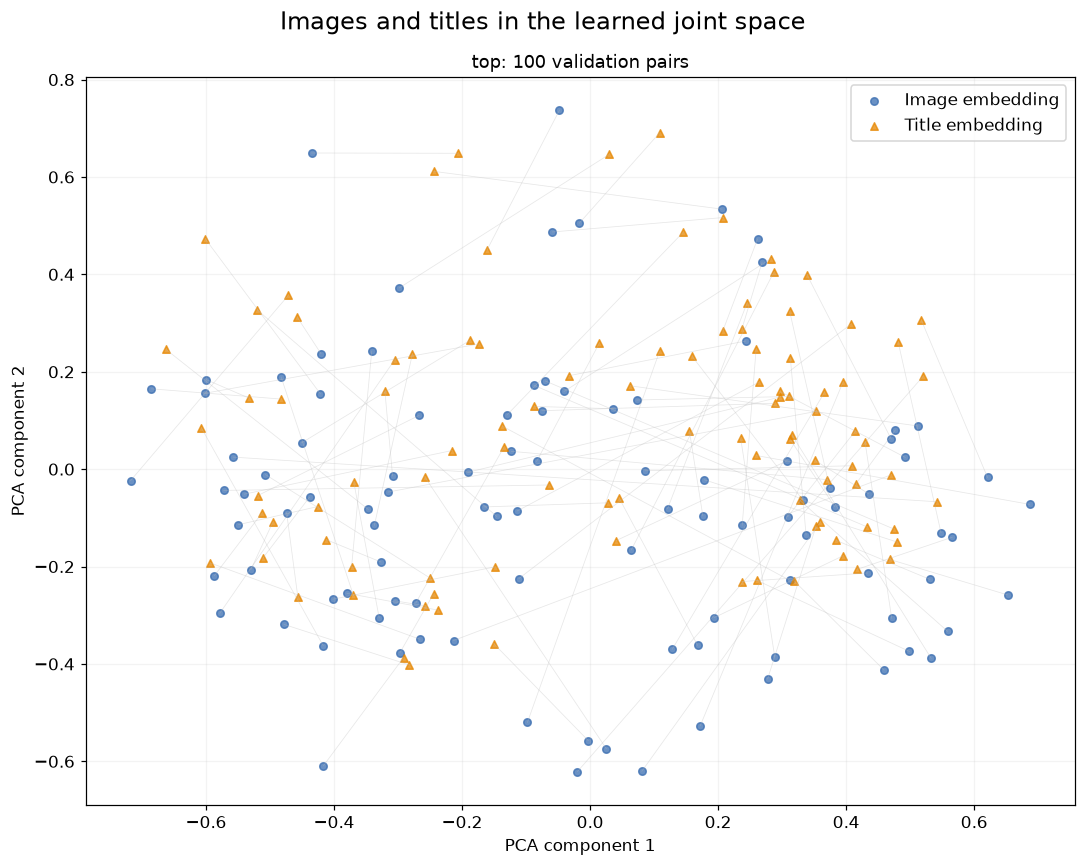

In [8]:
n=min(100,len(r['rows'])); both=np.vstack([r['I'][:n],r['T'][:n]]); xy=PCA(n_components=2,random_state=42).fit_transform(both); xi,xt=xy[:n],xy[n:]
fig,ax=plt.subplots(figsize=(10,8))
for i in range(n): ax.plot([xi[i,0],xt[i,0]],[xi[i,1],xt[i,1]],color='#BBBBBB',lw=.5,alpha=.35)
ax.scatter(xi[:,0],xi[:,1],s=24,color=COLORS['blue'],alpha=.75,label='Image embedding')
ax.scatter(xt[:,0],xt[:,1],s=24,color=COLORS['orange'],alpha=.75,marker='^',label='Title embedding')
ax.set_xlabel('PCA component 1'); ax.set_ylabel('PCA component 2'); ax.set_title(f'{CATEGORY}: {n} validation pairs'); ax.legend(); ax.grid(alpha=.15)
fig.suptitle('Images and titles in the learned joint space')
fig.tight_layout(); savefig(fig,'figure_3_6_6_joint_embedding_geometry')

## Report-ready synthesis and exported files

In [9]:
weighted_gap=np.average(metrics.cosine_gap,weights=metrics.validation_pairs)
print('REPORT-READY SYNTHESIS')
print(f"{len(trained)} category-specific 512-dimensional visual–semantic embedding models were trained from weak image–title pairs. Across the reconstructed validation sets, the validation-pair-weighted mean separation between matched and sampled mismatched cosine similarities was {weighted_gap:.3f}. Exact-pair retrieval varied across categories and directions; these scores quantify weak-pair alignment rather than independently verified visual-attribute accuracy. The similarity distributions and matrices show that matched pairs receive higher scores on average, while substantial overlap remains, consistent with noisy, sparse, and often non-visual seller-title content.")
print('\nGenerated files:')
for p in sorted(FIG_DIR.iterdir()): print(' -',p.relative_to(ROOT))

REPORT-READY SYNTHESIS
8 category-specific 512-dimensional visual–semantic embedding models were trained from weak image–title pairs. Across the reconstructed validation sets, the validation-pair-weighted mean separation between matched and sampled mismatched cosine similarities was 0.217. Exact-pair retrieval varied across categories and directions; these scores quantify weak-pair alignment rather than independently verified visual-attribute accuracy. The similarity distributions and matrices show that matched pairs receive higher scores on average, while substantial overlap remains, consistent with noisy, sparse, and often non-visual seller-title content.

Generated files:
 - outputs\figures\joint_embedding\3_6_1_embedding_run_summary.csv
 - outputs\figures\joint_embedding\3_6_validation_alignment_metrics.csv
 - outputs\figures\joint_embedding\figure_3_6_1_embedding_inputs.png
 - outputs\figures\joint_embedding\figure_3_6_1_embedding_inputs.svg
 - outputs\figures\joint_embedding\figu